[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/05-deep-learning-llms/03_cnn.ipynb)

*Deep Learning & LLMs · Notebook 3 of 10*

# Convolutional Networks

How networks see: convolution by hand, stride and padding, output sizes, parameter counts, pooling, receptive fields, channels, 1×1 convolutions and residual connections.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A CNN slides small detectors over an image: first edges, then shapes, then whole objects.

**What interviewers really test here:** Output-size calculation, parameter sharing, pooling, receptive fields and ResNet.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Why not just use dense layers on images? *(Basics)*
- [ ] 2. 1-D convolution by hand *(Basics)*
- [ ] 3. 2-D convolution and finding edges *(Core)*
- [ ] 4. Stride, padding and output size *(Core)*
- [ ] 5. Pooling and the receptive field *(Core)*
- [ ] 6. 1×1 convolutions and residual connections *(Advanced)*
- [ ] 7. Transfer learning and a CNN in PyTorch *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Formulas

| Quantity | Formula |
| --- | --- |
| Output size | ⌊(n + 2p − k)/s⌋ + 1 |
| Parameters | (k\_h·k\_w·c\_in + 1)·c\_out |
| Multiplications | k\_h·k\_w·c\_in·c\_out·H·W |
| Receptive field | r ← r + (k − 1)·j; j ← j·s |



Parameters don't depend on image size, while operations do. A cheap-to-store model can still be slow.

### Beyond plain convolution

| Variant | Idea |
| --- | --- |
| Dilated | gaps in the kernel: larger view, same cost |
| Depthwise separable | per-channel filter + 1×1 mix; much cheaper |
| Transposed | upsamples, used in segmentation and generation |
| Vision transformer | attention over image patches; needs more data or pre-training |

### Common computer-vision tasks

| Task | Output |
| --- | --- |
| Classification | one label per image |
| Detection | boxes and labels |
| Segmentation | one label per pixel |
| Embedding | a vector for similarity search |

---
# Part 2: Lessons, step by step

## Lesson 1: Why not just use dense layers on images?

*Level: Basics*

A 224 × 224 colour image has 224 × 224 × 3 = 150,528 input values. A dense layer of only 64 neurons needs (150,528 + 1) × 64 = **9,633,856** parameters. A convolutional layer with 64 filters of size 3 × 3 needs (3 × 3 × 3 + 1) × 64 = **1,792**.



Two good assumptions about images make this possible:



- **Locality:** nearby pixels matter most. An edge is found from a small patch.
- **Weight sharing:** an edge detector useful in one corner is useful everywhere, so one filter slides over the whole image.



A result is **translation equivariance**: move the cat, and the filter's response moves with it.

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q8](#q8), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 2: 1-D convolution by hand

*Level: Basics*

x = 1, 2, 3, 4, 5 and kernel k = 1, 0, −1. Slide the kernel along, multiply and add:



| Position | Window | Calculation | Output |
| --- | --- | --- | --- |
| 0 | 1, 2, 3 | 1·1 + 2·0 + 3·(−1) | −2 |
| 1 | 2, 3, 4 | 2·1 + 3·0 + 4·(−1) | −2 |
| 2 | 3, 4, 5 | 3·1 + 4·0 + 5·(−1) | −2 |



This filter measures the change across its window. The input rises steadily, so the output is constant. Kernel (0.5, 0.5) would instead be a moving average.



In a CNN, **the kernel's numbers are learned**; nobody hand-designs them.



**Terminology:** strictly speaking this is *cross-correlation*. True maths convolution flips the kernel first. Deep learning calls this "convolution" anyway, and since the filter is learned, the flip doesn't matter.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

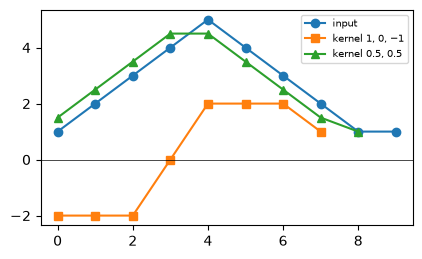

In [2]:
def conv_1d_steps():
    x = np.array([1, 2, 3, 4, 5, 4, 3, 2, 1, 1])
    change = np.correlate(x, [1, 0, -1], "valid")
    smooth = np.correlate(x, [0.5, 0.5], "valid")
    fig, ax = plt.subplots(figsize=(4.8, 2.8))
    ax.plot(x, "o-", label="input")
    ax.plot(change, "s-", label="kernel 1, 0, −1")
    ax.plot(smooth, "^-", label="kernel 0.5, 0.5")
    ax.axhline(0, color="black", linewidth=0.5)
    ax.legend(fontsize=7)


conv_1d_steps()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2). Try one now, or carry on and do them in Part 3.

## Lesson 3: 2-D convolution and finding edges

*Level: Core*

Here's an image with a vertical edge, and the Sobel filter:



```python
image = [[0, 0, 9, 9],      filter = [[-1, 0, 1],
         [0, 0, 9, 9],                [-2, 0, 2],
         [0, 0, 9, 9]]                [-1, 0, 1]]
```



On the top-left 3 × 3 patch, the filter gives (−0 + 9) + (−0 + 18) + (−0 + 9) = **36**. The next patch also gives 36. On a flat region, the left and right columns cancel to 0, so the filter "lights up" only at edges.



The chart applies filters to a simple picture. A CNN learns many such filters by itself. Early layers end up detecting edges and colours, and later layers respond to textures, parts and objects.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

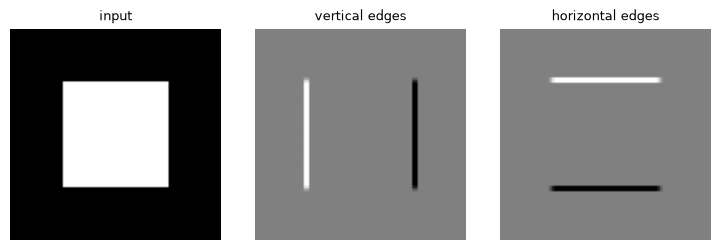

In [3]:
def filter_picture():
    from numpy.lib.stride_tricks import sliding_window_view
    x, y = np.meshgrid(np.linspace(-1, 1, 80), np.linspace(-1, 1, 80))
    image = ((np.abs(x) < 0.5) & (np.abs(y) < 0.5)).astype(float)
    vertical = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
    fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.5))
    results = [image, (sliding_window_view(image, (3, 3)) * vertical).sum(axis=(2, 3)), (sliding_window_view(image, (3, 3)) * vertical.T).sum(axis=(2, 3))]
    for ax, picture, name in zip(axes, results, ["input", "vertical edges", "horizontal edges"]):
        ax.imshow(picture, cmap="gray")
        ax.set_title(name, fontsize=9)
        ax.axis("off")
    fig.tight_layout()


filter_picture()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q4](#q4), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 4: Stride, padding and output size

*Level: Core*

**output = ⌊(n + 2p − k) / s⌋ + 1**



| n | Kernel k | Stride s | Padding p | Calculation | Output |
| --- | --- | --- | --- | --- | --- |
| 32 | 3 | 1 | 1 | (32 + 2 − 3)/1 + 1 | 32 (same size) |
| 32 | 2 | 2 | 0 | (32 − 2)/2 + 1 | 16 (halved) |
| 224 | 7 | 2 | 3 | ⌊223/2⌋ + 1 | 112 |



#### Tracking a whole network



32 → conv(3, 1, 1) → 32 → pool(2, 2) → 16 → conv(3, 1, 1) → 16 → pool(2, 2) → **8**. With 32 channels at the end, the classifier's input is 32 × 8 × 8 = **2,048**. Working this out wrongly is the most common CNN error, and it's why you should print shapes.



**Multiple channels:** an RGB filter has 3 × k × k weights and gives one output map. 64 filters give 64 maps.

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q17](#q17), [Q10](#q10), [Q20](#q20), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 5: Pooling and the receptive field

*Level: Core*

#### Pooling



**Max pooling** with size 2 turns each 2 × 2 block into its largest value. It halves the size and adds a little tolerance to small shifts. **Global average pooling** turns each whole map into one number, which removes the need for huge dense layers at the end.



#### Receptive field: how much does one output see?



For each layer: r ← r + (k − 1) × jump, then jump ← jump × s. Start with r = 1, jump = 1.



| Layer (k, s) | r | jump |
| --- | --- | --- |
| conv (3, 1) | 3 | 1 |
| pool (2, 2) | 4 | 2 |
| conv (3, 1) | 8 | 2 |
| pool (2, 2) | 10 | 4 |
| conv (3, 1) | 18 | 4 |



So three plain 3 × 3 layers see just 7 pixels, but with pooling, the same three see 18. To recognise an object, the receptive field must be about as big as the object.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

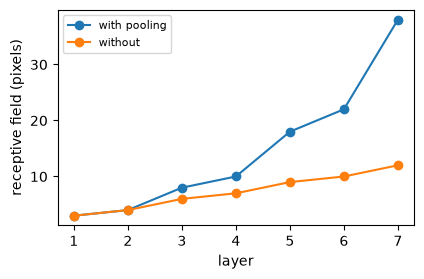

In [4]:
def receptive_growth():
    layers = [(3, 1), (2, 2), (3, 1), (2, 2), (3, 1), (2, 2), (3, 1)]
    pooled, plain = [], []
    r, jump = 1, 1
    for k, s in layers:
        r += (k - 1) * jump
        jump *= s
        pooled.append(r)
    r = 1
    for k, s in layers:
        r += k - 1
        plain.append(r)
    fig, ax = plt.subplots(figsize=(4.6, 2.8))
    ax.plot(range(1, 8), pooled, "o-", label="with pooling")
    ax.plot(range(1, 8), plain, "o-", label="without")
    ax.set_xlabel("layer")
    ax.set_ylabel("receptive field (pixels)")
    ax.legend(fontsize=8)


receptive_growth()

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q6](#q6), [Q7](#q7), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 6: 1×1 convolutions and residual connections

*Level: Advanced*

#### 1 × 1 convolutions



A 1 × 1 filter looks at one position across all channels, so it **mixes channels without changing height and width**. Going from 256 to 64 channels makes later layers far cheaper.



#### Residual connections: output = x + F(x)



Around 2015, researchers found that much deeper plain networks did *worse*, even on training data. ResNet's fix was to learn just the **change** F(x).



- **Doing nothing is easy:** with F's weights at zero, output = x. A new layer can't easily hurt.
- **Gradients flow:** the derivative of x + F(x) is 1 + F′(x), so the "1" gives gradients a direct route back. Without it they multiply and shrink.



This same idea appears in every transformer block.



| Architecture | Idea |
| --- | --- |
| VGG | stacks of 3 × 3 convolutions |
| ResNet | residual connections |
| MobileNet | cheap depthwise-separable convolutions |
| Vision Transformer | attention over image patches |

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

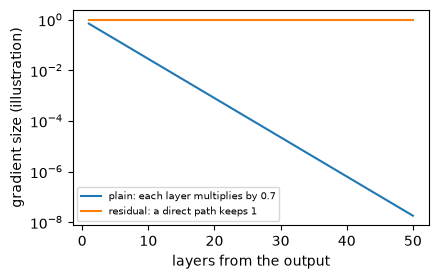

In [5]:
def residual_gradients():
    depths = np.arange(1, 51)
    plain = 0.7 ** depths
    residual = 1.0 + 0 * depths
    fig, ax = plt.subplots(figsize=(4.6, 2.8))
    ax.semilogy(depths, plain, label="plain: each layer multiplies by 0.7")
    ax.semilogy(depths, residual, label="residual: a direct path keeps 1")
    ax.set_xlabel("layers from the output")
    ax.set_ylabel("gradient size (illustration)")
    ax.legend(fontsize=7)


residual_gradients()

**✏️ Your turn:** you now have what you need for [Q18](#q18), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 7: Transfer learning and a CNN in PyTorch

*Level: Advanced*

You rarely train an image model from zero. **Transfer learning** reuses a network trained on millions of images:



1. Load a pre-trained model.
2. Replace the final layer with one for your classes.
3. Train only that layer first.
4. Optionally unfreeze more layers, with a small learning rate.



With a few hundred images per class, this often beats anything you could train from scratch. **Augmentation** helps too: random flips, crops and colour changes create new views. Check they make sense: rotating a "6" upside down makes a "9", so that label would be wrong.



```python
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(32 * 8 * 8, 10)

    def forward(self, x):                  # x: (N, 3, 32, 32)
        x = self.features(x)               # (N, 32, 8, 8)
        return self.classifier(x.flatten(1))   # (N, 10)
```

**✏️ Your turn:** you now have what you need for [Q12](#q12). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [6]:
from numpy.lib.stride_tricks import sliding_window_view


<a id="q1"></a>
### Q1. 1-D Convolution

🟢 Warm-up · *Slide and multiply*

Slide kernel k along x with no padding (no flipping, as deep learning does) and return the dot product at each position.

**Examples**

- `x = [1, 2, 3, 4, 5], k = [1, 0, -1]` → `[-2, -2, -2]`
- `x = [2, 4, 6], k = [0.5, 0.5]` → `[3.0, 5.0]`

In [ ]:
def conv1d(x, k):
    """
    Slide kernel k along x with no padding (no flipping, as deep learning does)
    and return the dot product at each position.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(conv1d, [
    (([1, 2, 3, 4, 5], [1, 0, -1]), [-2, -2, -2]),
    (([2, 4, 6], [0.5, 0.5]), [3.0, 5.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.correlate(x, k, 'valid')`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Two nested loops.

```python
def conv1d(x, k):
    out = []
    for i in range(len(x) - len(k) + 1):
        out.append(sum(x[i + j] * k[j] for j in range(len(k))))
    return out
```

**Cost:** O(n·k) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.correlate(x, k, 'valid')`.

```python
def conv1d(x, k):
    return np.correlate(x, k, "valid")
```

**Cost:** O(n·k) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two nested loops. That costs O(n·k) time and O(n) space."

"I can do better: `np.correlate(x, k, 'valid')`. That's O(n·k) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/1-d-convolution)

<a id="q2"></a>
### Q2. 1-D Convolution With Padding

🟢 Warm-up · *Keep the edges*

Add p zeros to each end of x, then convolve.

**Examples**

- `x = [1, 2, 3], k = [1, 1, 1], p = 1` → `[3, 6, 5]`

In [ ]:
def conv1d_pad(x, k, p):
    """
    Add p zeros to each end of x, then convolve.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(conv1d_pad, [
    (([1, 2, 3], [1, 1, 1], 1), [3, 6, 5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build the padded list, then two loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.pad` and `np.correlate`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Build the padded list, then two loops.

```python
def conv1d_pad(x, k, p):
    x = [0] * p + list(x) + [0] * p
    return [sum(x[i + j] * k[j] for j in range(len(k))) for i in range(len(x) - len(k) + 1)]
```

**Cost:** O(n·k) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.pad` and `np.correlate`.

```python
def conv1d_pad(x, k, p):
    return np.correlate(np.pad(x, p), k, "valid")
```

**Cost:** O(n·k) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build the padded list, then two loops. That costs O(n·k) time and O(n) space."

"I can do better: `np.pad` and `np.correlate`. That's O(n·k) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/1-d-convolution-with-padding)

<a id="q3"></a>
### Q3. Output Size

🟢 Warm-up · *⌊(n + 2p − k)/s⌋ + 1*

Return how many positions a kernel of size k fits along n, with padding p and stride s.

**Examples**

- `n = 224, k = 7, s = 2, p = 3` → `112`
- `n = 32, k = 3, s = 1, p = 1` → `32`
- `n = 5, k = 2, s = 2, p = 0` → `2`

In [ ]:
def output_size(n, k, s, p):
    """
    Return how many positions a kernel of size k fits along n, with padding p
    and stride s.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(output_size, [
    ((224, 7, 2, 3), 112),
    ((32, 3, 1, 1), 32),
    ((5, 2, 2, 0), 2),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Walk the kernel along, counting positions.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The formula.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Walk the kernel along, counting positions.

```python
def output_size(n, k, s, p):
    total, start, count = n + 2 * p, 0, 0
    while start + k <= total:
        count += 1
        start += s
    return count
```

**Cost:** O(n / s) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** The formula.

```python
def output_size(n, k, s, p):
    return (n + 2 * p - k) // s + 1
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Walk the kernel along, counting positions. That costs O(n / s) time and O(1) space."

"I can do better: The formula. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/output-size)

<a id="q4"></a>
### Q4. Detect a Vertical Edge

🟢 Warm-up · *The Sobel filter*

Apply the Sobel filter [[−1, 0, 1], [−2, 0, 2], [−1, 0, 1]] to the image.

**Examples**

- `img = [[0, 0, 9, 9], [0, 0, 9, 9], [0, 0, 9, 9]]` → `[[36, 36]]`

In [ ]:
SOBEL = [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]

def sobel(img):
    """
    Apply the Sobel filter [[−1, 0, 1], [−2, 0, 2], [−1, 0, 1]] to the image.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sobel, [
    (([[0, 0, 9, 9], [0, 0, 9, 9], [0, 0, 9, 9]],), [[36, 36]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Four nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Patch windows and a sum.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Four nested loops.

```python
def conv2d_loops(img, kernel, stride=1):
    h, w = len(img), len(img[0])
    kh, kw = len(kernel), len(kernel[0])
    out = []
    for i in range(0, h - kh + 1, stride):
        row = []
        for j in range(0, w - kw + 1, stride):
            row.append(sum(img[i + a][j + b] * kernel[a][b] for a in range(kh) for b in range(kw)))
        out.append(row)
    return out


def sobel(img):
    return conv2d_loops(img, SOBEL)
```

**Cost:** O(h·w) time, O(h·w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Patch windows and a sum.

```python
def sobel(img):
    k = np.array(SOBEL)
    return (sliding_window_view(np.array(img), k.shape) * k).sum(axis=(2, 3))
```

**Cost:** O(h·w) time, O(h·w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Four nested loops. That costs O(h·w) time and O(h·w) space."

"I can do better: Patch windows and a sum. That's O(h·w) time and O(h·w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/detect-a-vertical-edge)

<a id="q5"></a>
### Q5. Max Pooling

🟢 Warm-up · *Keep the strongest*

Apply k × k max pooling with stride k.

**Examples**

- `img = [[1, 2, 3, 0], [4, 5, 6, 1], [7, 8, 9, 2], [1, 0, 1, 3]], k = 2` → `[[5, 6], [8, 9]]`

In [ ]:
def max_pool(img, k):
    """
    Apply k × k max pooling with stride k.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(max_pool, [
    (([[1, 2, 3, 0], [4, 5, 6, 1], [7, 8, 9, 2], [1, 0, 1, 3]], 2), [[5, 6], [8, 9]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops over blocks.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Windows, then `.max(axis=(2, 3))`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops over blocks.

```python
def max_pool(img, k):
    out = []
    for i in range(0, len(img) - k + 1, k):
        row = []
        for j in range(0, len(img[0]) - k + 1, k):
            row.append(max(img[i + a][j + b] for a in range(k) for b in range(k)))
        out.append(row)
    return out
```

**Cost:** O(h·w) time, O(h·w/k²) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Windows, then `.max(axis=(2, 3))`.

```python
def max_pool(img, k):
    return sliding_window_view(np.array(img), (k, k))[::k, ::k].max(axis=(2, 3))
```

**Cost:** O(h·w) time, O(h·w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops over blocks. That costs O(h·w) time and O(h·w/k²) space."

"I can do better: Windows, then `.max(axis=(2, 3))`. That's O(h·w) time and O(h·w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/max-pooling)

<a id="q6"></a>
### Q6. Average Pooling

🟢 Warm-up · *Smooth and shrink*

Apply k × k average pooling with stride k, rounded to 4 decimals.

**Examples**

- `img = [[1, 2, 3, 0], [4, 5, 6, 1], [7, 8, 9, 2], [1, 0, 1, 3]], k = 2` → `[[3.0, 2.5], [4.0, 3.75]]`

In [ ]:
def avg_pool(img, k):
    """
    Apply k × k average pooling with stride k, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(avg_pool, [
    (([[1, 2, 3, 0], [4, 5, 6, 1], [7, 8, 9, 2], [1, 0, 1, 3]], 2), [[3.0, 2.5], [4.0, 3.75]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops over blocks.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Windows, then `.mean(axis=(2, 3))`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops over blocks.

```python
def avg_pool(img, k):
    out = []
    for i in range(0, len(img) - k + 1, k):
        row = []
        for j in range(0, len(img[0]) - k + 1, k):
            row.append(round(sum(img[i + a][j + b] for a in range(k) for b in range(k)) / (k * k), 4))
        out.append(row)
    return out
```

**Cost:** O(h·w) time, O(h·w/k²) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Windows, then `.mean(axis=(2, 3))`.

```python
def avg_pool(img, k):
    return sliding_window_view(np.array(img, dtype=float), (k, k))[::k, ::k].mean(axis=(2, 3)).round(4)
```

**Cost:** O(h·w) time, O(h·w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops over blocks. That costs O(h·w) time and O(h·w/k²) space."

"I can do better: Windows, then `.mean(axis=(2, 3))`. That's O(h·w) time and O(h·w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/average-pooling)

<a id="q7"></a>
### Q7. Global Average Pooling

🟢 Warm-up · *One number per channel*

Input is (channels, height, width). Return the average of each channel, rounded to 4 decimals.

**Examples**

- `x = [[[1, 2], [3, 4]], [[0, 0], [0, 8]]]` → `[2.5, 2.0]`

In [ ]:
def global_avg(x):
    """
    Input is (channels, height, width). Return the average of each channel,
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(global_avg, [
    (([[[1, 2], [3, 4]], [[0, 0], [0, 8]]],), [2.5, 2.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add everything in loops per channel.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`x.mean(axis=(1, 2))`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add everything in loops per channel.

```python
def global_avg(x):
    out = []
    for channel in x:
        values = [v for row in channel for v in row]
        out.append(round(sum(values) / len(values), 4))
    return out
```

**Cost:** O(c·h·w) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `x.mean(axis=(1, 2))`.

```python
def global_avg(x):
    return np.array(x, dtype=float).mean(axis=(1, 2)).round(4)
```

**Cost:** O(c·h·w) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add everything in loops per channel. That costs O(c·h·w) time and O(c) space."

"I can do better: `x.mean(axis=(1, 2))`. That's O(c·h·w) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/global-average-pooling)

<a id="q8"></a>
### Q8. Parameters in a Conv Layer

🟢 Warm-up · *(k·k·in + 1)·out*

Return the number of learnable parameters, including one bias per filter.

**Examples**

- `k = 3, in_channels = 3, out_channels = 64` → `1792`
- `k = 5, in_channels = 64, out_channels = 128` → `204928`

In [ ]:
def conv_params(k, in_channels, out_channels):
    """
    Return the number of learnable parameters, including one bias per filter.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(conv_params, [
    ((3, 3, 64), 1792),
    ((5, 64, 128), 204928),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add up each filter's weights and bias in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The formula.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add up each filter's weights and bias in a loop.

```python
def conv_params(k, in_channels, out_channels):
    total = 0
    for _ in range(out_channels):
        total += k * k * in_channels + 1
    return total
```

**Cost:** O(out) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** The formula.

```python
def conv_params(k, in_channels, out_channels):
    return (k * k * in_channels + 1) * out_channels
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add up each filter's weights and bias in a loop. That costs O(out) time and O(1) space."

"I can do better: The formula. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/parameters-in-a-conv-layer)

<a id="q9"></a>
### Q9. Dense vs Conv Parameters

🟢 Warm-up · *Why CNNs exist*

For an h × w × c image, compare a dense layer with \`units\` outputs against a 3 × 3 conv layer with the same number of filters. Return (dense params, conv params).

**Examples**

- `h = 224, w = 224, c = 3, units = 64` → `(9633856, 1792)`
- `h = 32, w = 32, c = 3, units = 16` → `(49168, 448)`

In [ ]:
def dense_vs_conv(h, w, c, units):
    """
    For an h × w × c image, compare a dense layer with `units` outputs against a
    3 × 3 conv layer with the same number of filters. Return (dense params, conv
    params).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dense_vs_conv, [
    ((224, 224, 3, 64), (9633856, 1792)),
    ((32, 32, 3, 16), (49168, 448)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply the sizes step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One formula each.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Multiply the sizes step by step.

```python
def dense_vs_conv(h, w, c, units):
    inputs = h * w * c
    dense_weights = inputs * units
    dense_total = dense_weights + units
    filter_weights = 3 * 3 * c
    conv_total = (filter_weights + 1) * units
    return (dense_total, conv_total)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One formula each.

```python
def dense_vs_conv(h, w, c, units):
    return ((h * w * c + 1) * units, (9 * c + 1) * units)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply the sizes step by step. That costs O(1) time and O(1) space."

"I can do better: One formula each. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/dense-vs-conv-parameters)

<a id="q10"></a>
### Q10. Flatten Size for the Classifier

🟢 Warm-up · *The number everyone gets wrong*

After convolutions the tensor has (channels, h, w). Return the input size for the first dense layer.

**Examples**

- `channels = 64, h = 8, w = 8` → `4096`
- `channels = 512, h = 7, w = 7` → `25088`

In [ ]:
def flatten_size(channels, h, w):
    """
    After convolutions the tensor has (channels, h, w). Return the input size
    for the first dense layer.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(flatten_size, [
    ((64, 8, 8), 4096),
    ((512, 7, 7), 25088),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply the three sizes.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.prod`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Multiply the three sizes.

```python
def flatten_size(channels, h, w):
    return channels * h * w
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.prod`.

```python
def flatten_size(channels, h, w):
    return int(np.prod([channels, h, w]))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply the three sizes. That costs O(1) time and O(1) space."

"I can do better: `np.prod`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/flatten-size-for-the-classifier)

<a id="q11"></a>
### Q11. Normalise Image Channels

🟢 Warm-up · *Mean and std per colour*

x is (channels, h, w). Subtract each channel's given mean and divide by its std. Round to 4 decimals.

**Examples**

- `x = [[[0.5, 1.0]], [[0.0, 0.5]]], mean = [0.5, 0.25], std = [0.5, 0.25]` → `[[[0.0, 1.0]], [[-1.0, 1.0]]]`

In [ ]:
def normalise_channels(x, mean, std):
    """
    x is (channels, h, w). Subtract each channel's given mean and divide by its
    std. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(normalise_channels, [
    (([[[0.5, 1.0]], [[0.0, 0.5]]], [0.5, 0.25], [0.5, 0.25]), [[[0.0, 1.0]], [[-1.0, 1.0]]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Three loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Broadcast with `mean[:, None, None]`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Three loops.

```python
def normalise_channels(x, mean, std):
    return [[[round((v - m) / s, 4) + 0.0 for v in row] for row in channel] for channel, m, s in zip(x, mean, std)]
```

**Cost:** O(c·h·w) time, O(c·h·w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Broadcast with `mean[:, None, None]`.

```python
def normalise_channels(x, mean, std):
    x, mean, std = np.array(x), np.array(mean), np.array(std)
    return ((x - mean[:, None, None]) / std[:, None, None]).round(4) + 0.0
```

**Cost:** O(c·h·w) time, O(c·h·w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Three loops. That costs O(c·h·w) time and O(c·h·w) space."

"I can do better: Broadcast with `mean[:, None, None]`. That's O(c·h·w) time and O(c·h·w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/normalise-image-channels)

<a id="q12"></a>
### Q12. Flip Augmentation

🟢 Warm-up · *More data for free*

Flip each row of the image left to right.

**Examples**

- `img = [[1, 2, 3], [4, 5, 6]]` → `[[3, 2, 1], [6, 5, 4]]`

In [ ]:
def flip(img):
    """
    Flip each row of the image left to right.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(flip, [
    (([[1, 2, 3], [4, 5, 6]],), [[3, 2, 1], [6, 5, 4]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Reverse each row.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.fliplr`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Reverse each row.

```python
def flip(img):
    return [row[::-1] for row in img]
```

**Cost:** O(h·w) time, O(h·w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.fliplr`.

```python
def flip(img):
    return np.fliplr(np.array(img))
```

**Cost:** O(h·w) time, O(1) view space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Reverse each row. That costs O(h·w) time and O(h·w) space."

"I can do better: `np.fliplr`. That's O(h·w) time and O(1) view space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/flip-augmentation)

<a id="q13"></a>
### Q13. 2-D Convolution

🟡 Interview standard · *A filter over an image*

Return the convolution of img with the kernel (no padding, stride 1).

**Examples**

- `img = [[1, 2, 3, 0], [4, 5, 6, 1], [7, 8, 9, 2], [1, 0, 1, 3]], kernel = [[1, 0], [0, -1]]` → `[[-4, -4, 2], [-4, -4, 4], [7, 7, 6]]`

In [ ]:
def conv2d(img, kernel):
    """
    Return the convolution of img with the kernel (no padding, stride 1).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(conv2d, [
    (([[1, 2, 3, 0], [4, 5, 6, 1], [7, 8, 9, 2], [1, 0, 1, 3]], [[1, 0], [0, -1]]), [[-4, -4, 2], [-4, -4, 4], [7, 7, 6]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Four nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sliding_window_view` gives all patches at once; multiply and sum.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Four nested loops.

```python
def conv2d_loops(img, kernel, stride=1):
    h, w = len(img), len(img[0])
    kh, kw = len(kernel), len(kernel[0])
    out = []
    for i in range(0, h - kh + 1, stride):
        row = []
        for j in range(0, w - kw + 1, stride):
            row.append(sum(img[i + a][j + b] * kernel[a][b] for a in range(kh) for b in range(kw)))
        out.append(row)
    return out


def conv2d(img, kernel):
    return conv2d_loops(img, kernel)
```

**Cost:** O(h·w·k²) time, O(h·w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `sliding_window_view` gives all patches at once; multiply and sum.

```python
def conv2d(img, kernel):
    kernel = np.array(kernel)
    windows = sliding_window_view(np.array(img), kernel.shape)
    return (windows * kernel).sum(axis=(2, 3))
```

**Cost:** O(h·w·k²) time, O(h·w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Four nested loops. That costs O(h·w·k²) time and O(h·w) space."

"I can do better: `sliding_window_view` gives all patches at once; multiply and sum. That's O(h·w·k²) time and O(h·w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/2-d-convolution)

<a id="q14"></a>
### Q14. Convolution With Stride

🟡 Interview standard · *Skip positions*

Convolve with stride s in both directions.

**Examples**

- `img = [[1, 2, 3, 0], [4, 5, 6, 1], [7, 8, 9, 2], [1, 0, 1, 3]], kernel = [[1, 0], [0, -1]], s = 2` → `[[-4, 2], [7, 6]]`

In [ ]:
def conv2d_stride(img, kernel, s):
    """
    Convolve with stride s in both directions.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(conv2d_stride, [
    (([[1, 2, 3, 0], [4, 5, 6, 1], [7, 8, 9, 2], [1, 0, 1, 3]], [[1, 0], [0, -1]], 2), [[-4, 2], [7, 6]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Step the loops by s.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Patch windows, then slice `[::s, ::s]`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Step the loops by s.

```python
def conv2d_loops(img, kernel, stride=1):
    h, w = len(img), len(img[0])
    kh, kw = len(kernel), len(kernel[0])
    out = []
    for i in range(0, h - kh + 1, stride):
        row = []
        for j in range(0, w - kw + 1, stride):
            row.append(sum(img[i + a][j + b] * kernel[a][b] for a in range(kh) for b in range(kw)))
        out.append(row)
    return out


def conv2d_stride(img, kernel, s):
    return conv2d_loops(img, kernel, s)
```

**Cost:** O(h·w·k²/s²) time, O(h·w/s²) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Patch windows, then slice `[::s, ::s]`.

```python
def conv2d_stride(img, kernel, s):
    kernel = np.array(kernel)
    windows = sliding_window_view(np.array(img), kernel.shape)[::s, ::s]
    return (windows * kernel).sum(axis=(2, 3))
```

**Cost:** O(h·w) time, O(h·w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Step the loops by s. That costs O(h·w·k²/s²) time and O(h·w/s²) space."

"I can do better: Patch windows, then slice `[::s, ::s]`. That's O(h·w) time and O(h·w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/convolution-with-stride)

<a id="q15"></a>
### Q15. Operations in a Conv Layer

🟡 Interview standard · *Parameters aren't cost*

Return the multiplications for one image: k·k·in·out·H·W, where H × W is the output size (no bias).

**Examples**

- `k = 3, c_in = 3, c_out = 64, H = 222, W = 222` → `85162752`
- `k = 3, c_in = 64, c_out = 128, H = 110, W = 110` → `892108800`

In [ ]:
def conv_ops(k, c_in, c_out, H, W):
    """
    Return the multiplications for one image: k·k·in·out·H·W, where H × W is the
    output size (no bias).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(conv_ops, [
    ((3, 3, 64, 222, 222), 85162752),
    ((3, 64, 128, 110, 110), 892108800),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count one output position's work, then multiply up.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.prod` of all the factors.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count one output position's work, then multiply up.

```python
def conv_ops(k, c_in, c_out, H, W):
    per_filter_position = k * k * c_in
    per_position = per_filter_position * c_out
    return per_position * H * W
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.prod` of all the factors.

```python
def conv_ops(k, c_in, c_out, H, W):
    return int(np.prod([k, k, c_in, c_out, H, W], dtype=np.int64))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count one output position's work, then multiply up. That costs O(1) time and O(1) space."

"I can do better: `np.prod` of all the factors. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/operations-in-a-conv-layer)

<a id="q16"></a>
### Q16. Receptive Field

🟡 Interview standard · *How much each output sees*

Layers are (kernel, stride) pairs. Return the size of the input region seen by one output of the last layer.

**Examples**

- `layers = [(3, 1), (3, 1), (3, 1)]` → `7`
- `layers = [(3, 1), (2, 2), (3, 1), (2, 2), (3, 1)]` → `18`

In [ ]:
def receptive_field(layers):
    """
    Layers are (kernel, stride) pairs. Return the size of the input region seen
    by one output of the last layer.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(receptive_field, [
    (([(3, 1), (3, 1), (3, 1)],), 7),
    (([(3, 1), (2, 2), (3, 1), (2, 2), (3, 1)],), 18),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

r ← r + (k − 1)·jump, then jump ← jump·s, in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised: `1 + Σ (k−1)·Π(previous strides)` with `np.cumprod`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** r ← r + (k − 1)·jump, then jump ← jump·s, in a loop.

```python
def receptive_field(layers):
    r, jump = 1, 1
    for k, s in layers:
        r += (k - 1) * jump
        jump *= s
    return r
```

**Cost:** O(L) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Vectorised: `1 + Σ (k−1)·Π(previous strides)` with `np.cumprod`.

```python
def receptive_field(layers):
    a = np.array(layers)
    jumps = np.r_[1, np.cumprod(a[:, 1])[:-1]]
    return int(1 + ((a[:, 0] - 1) * jumps).sum())
```

**Cost:** O(L) time, O(L) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: r ← r + (k − 1)·jump, then jump ← jump·s, in a loop. That costs O(L) time and O(1) space."

"I can do better: Vectorised: `1 + Σ (k−1)·Π(previous strides)` with `np.cumprod`. That's O(L) time and O(L) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/receptive-field)

<a id="q17"></a>
### Q17. Shape Through a Network

🟡 Interview standard · *Track sizes before coding*

Start at size n. Each layer is (k, s, p). Return the size after each layer.

**Examples**

- `n = 32, layers = [(3, 1, 1), (2, 2, 0), (3, 1, 1), (2, 2, 0)]` → `[32, 16, 16, 8]`
- `n = 224, layers = [(7, 2, 3), (3, 2, 1)]` → `[112, 56]`

In [ ]:
def sizes_through(n, layers):
    """
    Start at size n. Each layer is (k, s, p). Return the size after each layer.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sizes_through, [
    ((32, [(3, 1, 1), (2, 2, 0), (3, 1, 1), (2, 2, 0)]), [32, 16, 16, 8]),
    ((224, [(7, 2, 3), (3, 2, 1)]), [112, 56]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count the positions layer by layer.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The formula in a loop.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count the positions layer by layer.

```python
def sizes_through(n, layers):
    out = []
    for k, s, p in layers:
        total, start, count = n + 2 * p, 0, 0
        while start + k <= total:
            count += 1
            start += s
        n = count
        out.append(n)
    return out
```

**Cost:** O(L·n) time, O(L) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** The formula in a loop.

```python
def sizes_through(n, layers):
    out = []
    for k, s, p in layers:
        n = (n + 2 * p - k) // s + 1
        out.append(n)
    return out
```

**Cost:** O(L) time, O(L) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count the positions layer by layer. That costs O(L·n) time and O(L) space."

"I can do better: The formula in a loop. That's O(L) time and O(L) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/shape-through-a-network)

<a id="q18"></a>
### Q18. 1×1 Convolution

🟡 Interview standard · *Mix channels, keep the size*

x is (channels, h, w). W has one row per output channel and one column per input channel. Return the mixed result.

**Examples**

- `x = [[[1, 2]], [[3, 4]]], W = [[1, 1], [1, -1]]` → `[[[4, 6]], [[-2, -2]]]`

In [ ]:
def conv_1x1(x, W):
    """
    x is (channels, h, w). W has one row per output channel and one column per
    input channel. Return the mixed result.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(conv_1x1, [
    (([[[1, 2]], [[3, 4]]], [[1, 1], [1, -1]]), [[[4, 6]], [[-2, -2]]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over each pixel position, mixing channel values.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.tensordot(W, x, axes=1)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loop over each pixel position, mixing channel values.

```python
def conv_1x1(x, W):
    c_in, h, w = len(x), len(x[0]), len(x[0][0])
    out = []
    for row in W:
        channel = []
        for i in range(h):
            channel.append([sum(row[c] * x[c][i][j] for c in range(c_in)) for j in range(w)])
        out.append(channel)
    return out
```

**Cost:** O(h·w·c²) time, O(h·w·c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.tensordot(W, x, axes=1)`.

```python
def conv_1x1(x, W):
    return np.tensordot(np.array(W), np.array(x), axes=1)
```

**Cost:** O(h·w·c²) time, O(h·w·c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over each pixel position, mixing channel values. That costs O(h·w·c²) time and O(h·w·c) space."

"I can do better: `np.tensordot(W, x, axes=1)`. That's O(h·w·c²) time and O(h·w·c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/1-1-convolution)

<a id="q19"></a>
### Q19. A Residual Block

🟡 Interview standard · *Output = x + F(x)*

Given x and matrices W1, W2, return x + ReLU(x·W1)·W2, rounded to 4 decimals.

**Examples**

- `x = [[1.0, 2.0]], W1 = [[1.0, 0.0], [0.0, 1.0]], W2 = [[0.5, 0.0], [0.0, 0.5]]` → `[[1.5, 3.0]]`
- `x = [[1.0, 2.0]], W1 = [[0.0, 0.0], [0.0, 0.0]], W2 = [[1.0, 1.0], [1.0, 1.0]]` → `[[1.0, 2.0]]`

In [ ]:
def residual(x, W1, W2):
    """
    Given x and matrices W1, W2, return x + ReLU(x·W1)·W2, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(residual, [
    (([[1.0, 2.0]], [[1.0, 0.0], [0.0, 1.0]], [[0.5, 0.0], [0.0, 0.5]]), [[1.5, 3.0]]),
    (([[1.0, 2.0]], [[0.0, 0.0], [0.0, 0.0]], [[1.0, 1.0], [1.0, 1.0]]), [[1.0, 2.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops for each matrix product.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`x + np.maximum(0, x @ W1) @ W2`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops for each matrix product.

```python
def residual(x, W1, W2):
    out = []
    for row in x:
        h = [max(0.0, sum(row[i] * W1[i][j] for i in range(len(row)))) for j in range(len(W1[0]))]
        f = [sum(h[i] * W2[i][j] for i in range(len(h))) for j in range(len(W2[0]))]
        out.append([round(a + b, 4) for a, b in zip(row, f)])
    return out
```

**Cost:** O(d²) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `x + np.maximum(0, x @ W1) @ W2`.

```python
def residual(x, W1, W2):
    x = np.array(x)
    return (x + np.maximum(0, x @ np.array(W1)) @ np.array(W2)).round(4)
```

**Cost:** O(d²) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops for each matrix product. That costs O(d²) time and O(d) space."

"I can do better: `x + np.maximum(0, x @ W1) @ W2`. That's O(d²) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/a-residual-block)

<a id="q20"></a>
### Q20. Convolution Across Channels

🔴 Stretch · *One filter sees all colours*

Input is (channels, h, w) and the filter is (channels, k, k). Return the single output map: the sum across channels of each channel's convolution.

**Examples**

- `x = [[[1, 2], [3, 4]], [[0, 1], [1, 0]]], kernel = [[[1]], [[10]]]` → `[[1, 12], [13, 4]]`
- `x = [[[1, 2, 0], [3, 4, 1]], [[0, 1, 1], [1, 0, 2]]], kernel = [[[1, -1]], [[2, 0]]]` → `[[-1, 4], [1, 3]]`

In [ ]:
def conv_channels(x, kernel):
    """
    Input is (channels, h, w) and the filter is (channels, k, k). Return the
    single output map: the sum across channels of each channel's convolution.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(conv_channels, [
    (([[[1, 2], [3, 4]], [[0, 1], [1, 0]]], [[[1]], [[10]]]), [[1, 12], [13, 4]]),
    (([[[1, 2, 0], [3, 4, 1]], [[0, 1, 1], [1, 0, 2]]], [[[1, -1]], [[2, 0]]]), [[-1, 4], [1, 3]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Convolve each channel separately and add the maps.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Windows over the height and width axes, then a sum over channels and kernel axes.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Convolve each channel separately and add the maps.

```python
def conv2d_loops(img, kernel, stride=1):
    h, w = len(img), len(img[0])
    kh, kw = len(kernel), len(kernel[0])
    out = []
    for i in range(0, h - kh + 1, stride):
        row = []
        for j in range(0, w - kw + 1, stride):
            row.append(sum(img[i + a][j + b] * kernel[a][b] for a in range(kh) for b in range(kw)))
        out.append(row)
    return out


def conv_channels(x, kernel):
    total = None
    for channel, k in zip(x, kernel):
        part = conv2d_loops(channel, k)
        if total is None:
            total = part
        else:
            total = [[a + b for a, b in zip(r1, r2)] for r1, r2 in zip(total, part)]
    return total
```

**Cost:** O(c·h·w·k²) time, O(h·w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Windows over the height and width axes, then a sum over channels and kernel axes.

```python
def conv_channels(x, kernel):
    x, kernel = np.array(x), np.array(kernel)
    windows = sliding_window_view(x, kernel.shape[1:], axis=(1, 2))
    return (windows * kernel[:, None, None]).sum(axis=(0, 3, 4))
```

**Cost:** O(c·h·w·k²) time, O(c·h·w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Convolve each channel separately and add the maps. That costs O(c·h·w·k²) time and O(h·w) space."

"I can do better: Windows over the height and width axes, then a sum over channels and kernel axes. That's O(c·h·w·k²) time and O(c·h·w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/cnn/convolution-across-channels)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why do CNNs need fewer parameters than dense networks?</b></summary>

Each filter only looks at a small patch (locality), and the same filter is reused across the image (weight sharing).

</details>

<details>
<summary><b>2. What does pooling do?</b></summary>

It shrinks the map, widens the receptive field and adds small shift tolerance, with no parameters to learn.

</details>

<details>
<summary><b>3. What is a receptive field?</b></summary>

The input region that can influence one output. It grows with depth and much faster with stride or pooling.

</details>

<details>
<summary><b>4. Why do residual connections help?</b></summary>

They make the identity easy to learn and give gradients a direct path back, so very deep networks can train.

</details>

<details>
<summary><b>5. What is transfer learning?</b></summary>

Reusing a model trained on a large dataset as the starting point for a new task, usually replacing the final layer.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Why not just use dense layers on images?
- [ ] I can explain: 1-D convolution by hand
- [ ] I can explain: 2-D convolution and finding edges
- [ ] I can explain: Stride, padding and output size
- [ ] I can explain: Pooling and the receptive field
- [ ] I can explain: 1×1 convolutions and residual connections
- [ ] I can explain: Transfer learning and a CNN in PyTorch

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Receptive Field
- [ ] [Q17](#q17) Shape Through a Network
- [ ] [Q18](#q18) 1×1 Convolution
- [ ] [Q19](#q19) A Residual Block
- [ ] [Q20](#q20) Convolution Across Channels

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.